# 01 — 探索分析（EDA）

**目的：** 睇清數據長甚麼樣、邊類客戶違約率較高、衍生欄位有無訊號，為建模打底。

**對照文件：** 項目骨架（`credit-default-project-skeleton.docx`）「Python：探索分析與建模步驟」一節。衍生欄位定義與骨架 `04_features.sql` 完全一致，SQL 層仍是正式的清洗層；此處用 pandas 做同一套特徵，令筆記本可以獨立跑通。

**數據：** UCI「Default of Credit Card Clients」— 台灣信用卡客戶，2005 年 4–9 月，30,000 行。**提醒：** 這是 2005 年的台灣舊數據，只適合做作品集示範，不代表現時香港市場。

## 0. 讀入前要知道的事

- 原始 Excel 第一行是標題行（X1、X2…），真正的欄位名在第二行，所以用 `header=1` 讀入。
- 讀入後先改名：`Y` → `default_payment_next_month`（1 = 下個月違約，0 = 無違約）。
- `PAY_0` 是最近月（2005 年 9 月），`PAY_6` 是最早月（4 月）；注意沒有 `PAY_1`。

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

RAW_NAME = "default of credit card clients.xls"

from pathlib import Path

# 找出項目根目錄：不論由 notebooks/ 還是項目根目錄執行都 work
_CANDIDATES = [Path.cwd(), Path.cwd().parent]
PROJECT_ROOT = next(
    (p for p in _CANDIDATES if (p / "data" / "raw" / RAW_NAME).exists()),
    Path.cwd().parent,
)
RAW_PATH = PROJECT_ROOT / "data" / "raw" / RAW_NAME
PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"
REPORTS_DIR = PROJECT_ROOT / "reports"
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)
REPORTS_DIR.mkdir(parents=True, exist_ok=True)
print("項目根目錄：", PROJECT_ROOT)
print("原始檔：", RAW_PATH, "存在：" , RAW_PATH.exists())

項目根目錄： /home/hatch/workspace/goals/credit-default-prediction-portfolio-project/files/credit-default-project
原始檔： /home/hatch/workspace/goals/credit-default-prediction-portfolio-project/files/credit-default-project/data/raw/default of credit card clients.xls 存在： True


In [2]:
# 讀入原始檔：header=1（第二行先係真正欄名）
df = pd.read_excel(RAW_PATH, header=1, engine="calamine")
df = df.rename(columns={"default payment next month": "default_payment_next_month"})

print("形狀（行，欄）：", df.shape)
print("ID 是否唯一：", df["ID"].is_unique)
print("缺失值總數：", int(df.isna().sum().sum()))
print("欄位：", list(df.columns))
df.head(3)

形狀（行，欄）： (30000, 25)
ID 是否唯一： True
缺失值總數： 0
欄位： ['ID', 'LIMIT_BAL', 'SEX', 'EDUCATION', 'MARRIAGE', 'AGE', 'PAY_0', 'PAY_2', 'PAY_3', 'PAY_4', 'PAY_5', 'PAY_6', 'BILL_AMT1', 'BILL_AMT2', 'BILL_AMT3', 'BILL_AMT4', 'BILL_AMT5', 'BILL_AMT6', 'PAY_AMT1', 'PAY_AMT2', 'PAY_AMT3', 'PAY_AMT4', 'PAY_AMT5', 'PAY_AMT6', 'default_payment_next_month']


,ID,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_0,PAY_2,PAY_3,PAY_4,...,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,default_payment_next_month
0,1,20000,2,2,1,24,2,2,-1,-1,...,0,0,0,0,689,0,0,0,0,1
1,2,120000,2,2,2,26,-1,2,0,0,...,3272,3455,3261,0,1000,1000,1000,0,2000,1
2,3,90000,2,2,2,34,0,0,0,0,...,14331,14948,15549,1518,1500,1000,1000,1000,5000,0


## 1. 目標欄位：違約是少數類別

違約客戶佔約兩成，是少數類別。之後所有評估都要按這個前提做：**準確率可以報，但永遠要同 AUC、recall、precision 一齊報**——如果模型把所有人預測成「不會違約」，準確率看起來仍然很高，但一個違約客戶都捉不到。

違約（1）： 6636 人
無違約（0）： 23364 人
整體違約率： 22.12 %


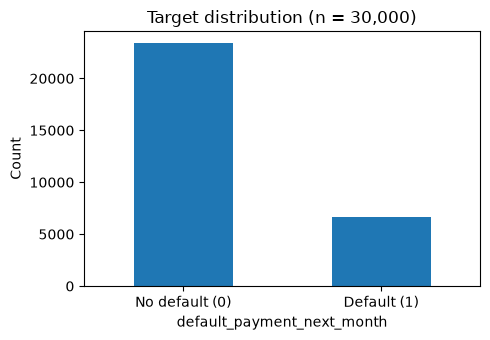

In [3]:
target = df["default_payment_next_month"]
print("違約（1）：", int((target == 1).sum()), "人")
print("無違約（0）：", int((target == 0).sum()), "人")
print("整體違約率：", round(target.mean() * 100, 2), "%")

ax = target.value_counts().sort_index().plot(kind="bar", figsize=(5, 3.5))
ax.set_xticklabels(["No default (0)", "Default (1)"], rotation=0)
ax.set_title("Target distribution (n = 30,000)")
ax.set_ylabel("Count")
plt.tight_layout()
plt.show()

## 2. 類別欄位體檢：先睇，唔好急住改

重點睇未知編碼藏喺邊：`EDUCATION` 除 1=研究所、2=大學、3=高中、4=其他之外，仲有 0、5、6；`MARRIAGE` 除 1=已婚、2=單身、3=其他之外，仲有 0。呢啲未知類別要合併處理，唔好刪行（骨架 C 部分）。

In [4]:
for col in ["SEX", "EDUCATION", "MARRIAGE"]:
    print(f"--- {col} ---")
    print(df[col].value_counts(dropna=False).sort_index().to_string())
    print()

print("--- PAY_0（最近月還款狀態）---")
print(df["PAY_0"].value_counts(dropna=False).sort_index().to_string())
print()
print("PAY 欄位量尺：-2 = 沒有消費；-1 = 準時還款；0 = 使用循環信用；1–9 = 延遲月數")

--- SEX ---
SEX
1    11888
2    18112

--- EDUCATION ---
EDUCATION
0       14
1    10585
2    14030
3     4917
4      123
5      280
6       51

--- MARRIAGE ---
MARRIAGE
0       54
1    13659
2    15964
3      323

--- PAY_0（最近月還款狀態）---
PAY_0
-2     2759
-1     5686
 0    14737
 1     3688
 2     2667
 3      322
 4       76
 5       26
 6       11
 7        9
 8       19

PAY 欄位量尺：-2 = 沒有消費；-1 = 準時還款；0 = 使用循環信用；1–9 = 延遲月數


## 3. 按還款狀態分組的違約率（PAY_0，最近月）

**睇法：** 延遲月數愈多，違約率應該愈高。如果某組違約率唔跟呢個方向走，要停低諗下係咪編碼理解錯（例如 -2、-1、0 唔係延遲）。

 PAY_0     n  default_rate  default_rate_pct
    -2  2759      0.132294              13.2
    -1  5686      0.167781              16.8
     0 14737      0.128113              12.8
     1  3688      0.339479              33.9
     2  2667      0.691414              69.1
     3   322      0.757764              75.8
     4    76      0.684211              68.4
     5    26      0.500000              50.0
     6    11      0.545455              54.5
     7     9      0.777778              77.8
     8    19      0.578947              57.9


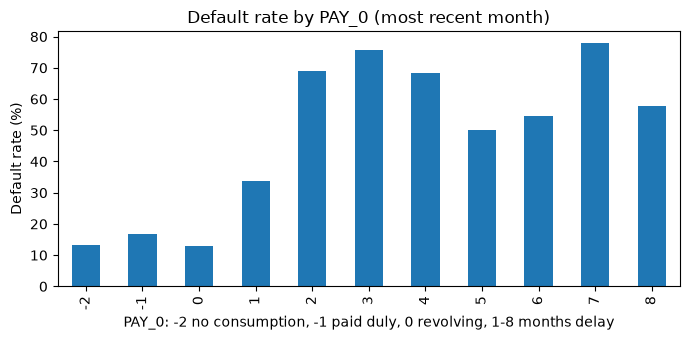

In [5]:
pay0_rate = (
    df.groupby("PAY_0")["default_payment_next_month"]
    .agg(n="size", default_rate="mean")
    .reset_index()
)
pay0_rate["default_rate_pct"] = (pay0_rate["default_rate"] * 100).round(1)
print(pay0_rate.to_string(index=False))

ax = pay0_rate.plot(kind="bar", x="PAY_0", y="default_rate_pct",
                    figsize=(7, 3.5), legend=False)
ax.set_title("Default rate by PAY_0 (most recent month)")
ax.set_xlabel("PAY_0: -2 no consumption, -1 paid duly, 0 revolving, 1-8 months delay")
ax.set_ylabel("Default rate (%)")
plt.tight_layout()
plt.show()

## 4. 按信用額度分組（LIMIT_BAL 四分位）

       limit_quartile    n  default_rate  default_rate_pct
  (9999.999, 50000.0] 7676      0.317874              31.8
  (50000.0, 140000.0] 7614      0.247176              24.7
 (140000.0, 240000.0] 7643      0.173492              17.3
(240000.0, 1000000.0] 7067      0.139805              14.0


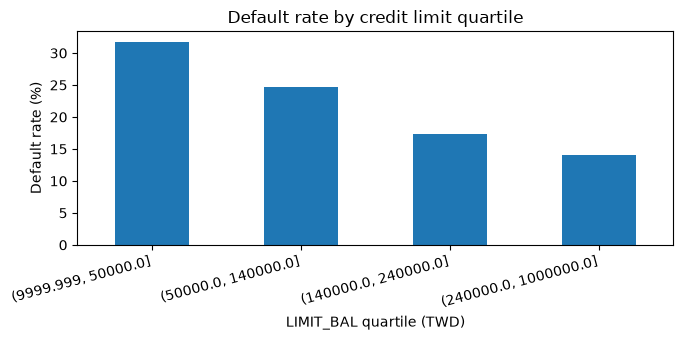

In [6]:
df["limit_quartile"] = pd.qcut(df["LIMIT_BAL"], 4, duplicates="drop")
limit_rate = (
    df.groupby("limit_quartile", observed=True)["default_payment_next_month"]
    .agg(n="size", default_rate="mean")
    .reset_index()
)
limit_rate["default_rate_pct"] = (limit_rate["default_rate"] * 100).round(1)
print(limit_rate.to_string(index=False))

ax = limit_rate.plot(kind="bar", x="limit_quartile", y="default_rate_pct",
                     figsize=(7, 3.5), legend=False)
ax.set_title("Default rate by credit limit quartile")
ax.set_xlabel("LIMIT_BAL quartile (TWD)")
ax.set_ylabel("Default rate (%)")
plt.xticks(rotation=15, ha="right")
plt.tight_layout()
plt.show()

## 5. 按教育程度／婚姻狀況分組

In [7]:
for col in ["EDUCATION", "MARRIAGE"]:
    t = (
        df.groupby(col)["default_payment_next_month"]
        .agg(n="size", default_rate="mean")
        .reset_index()
    )
    t["default_rate_pct"] = (t["default_rate"] * 100).round(1)
    print(f"--- {col} ---")
    print(t.to_string(index=False))
    print()

--- EDUCATION ---
 EDUCATION     n  default_rate  default_rate_pct
         0    14      0.000000               0.0
         1 10585      0.192348              19.2
         2 14030      0.237349              23.7
         3  4917      0.251576              25.2
         4   123      0.056911               5.7
         5   280      0.064286               6.4
         6    51      0.156863              15.7

--- MARRIAGE ---
 MARRIAGE     n  default_rate  default_rate_pct
        0    54      0.092593               9.3
        1 13659      0.234717              23.5
        2 15964      0.209283              20.9
        3   323      0.260062              26.0



## 6. 數值欄位分佈：違約 vs 無違約

睇兩組的描述統計和年齡分佈。`LIMIT_BAL` 分佈極右偏（少數人額度好高），之後建模要標準化；年齡分佈兩組差異唔大，唔好預期年齡係強訊號。

--- LIMIT_BAL / AGE by target ---
                           LIMIT_BAL                                                                           AGE                                         
                               count      mean       std      min      25%       50%       75%        max    count  mean  std   min   25%   50%   75%   max
default_payment_next_month                                                                                                                                 
0                            23364.0  178099.7  131628.4  10000.0  70000.0  150000.0  250000.0  1000000.0  23364.0  35.4  9.1  21.0  28.0  34.0  41.0  79.0
1                             6636.0  130109.7  115378.5  10000.0  50000.0   90000.0  200000.0   740000.0   6636.0  35.7  9.7  21.0  28.0  34.0  42.0  75.0


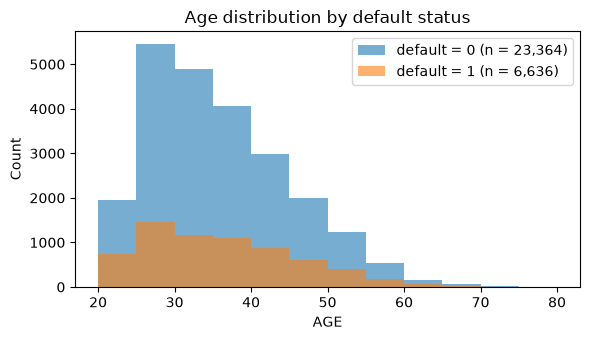

In [8]:
print("--- LIMIT_BAL / AGE by target ---")
print(df.groupby("default_payment_next_month")[["LIMIT_BAL", "AGE"]].describe().round(1).to_string())

fig, ax = plt.subplots(figsize=(6, 3.5))
for label, grp in df.groupby("default_payment_next_month"):
    ax.hist(grp["AGE"], bins=range(20, 81, 5), alpha=0.6,
            label=f"default = {label} (n = {len(grp):,})")
ax.set_title("Age distribution by default status")
ax.set_xlabel("AGE")
ax.set_ylabel("Count")
ax.legend()
plt.tight_layout()
plt.show()

## 7. 衍生欄位：將原始欄位變成風險訊號

定義與骨架 `04_features.sql` 完全一致，每個欄位都講得出業務含義：

| 衍生欄位 | 定義 | 業務含義 |
| --- | --- | --- |
| `utilisation_1` | BILL_AMT1 / LIMIT_BAL | 最近月用了幾多成額度 |
| `pay_ratio_1` | PAY_AMT1 / BILL_AMT1 | 最近月還了幾多成結單 |
| `pay_ratio_avg` | 6 個月 PAY_AMT 總和 / 6 個月 BILL_AMT 總和 | 半年整體還款行為 |
| `max_delay_6m` | 六個延遲月數的最大值 | 半年內最嚴重延遲 |
| `delay_months_cnt` | 六個月入面延遲 ≥ 1 個月的月份數 | 延遲是偶發還是習慣性 |
| `consecutive_delay` | 由最近月起連續延遲 ≥ 1 個月的月數，中斷即停 | 最近有無連續延遲 |
| `bill_trend` | BILL_AMT1 − BILL_AMT6 | 結單金額半年趨勢 |

`PAY` 原始編碼先轉做延遲月數（-2／-1／0 → 0，1–9 照原值），原欄位不覆寫。除零處理：分母為 0 或負數時設為缺失並標記，唔硬計比率。

In [9]:
pay_cols = ["PAY_0", "PAY_2", "PAY_3", "PAY_4", "PAY_5", "PAY_6"]
bill_cols = [f"BILL_AMT{i}" for i in range(1, 7)]
pay_amt_cols = [f"PAY_AMT{i}" for i in range(1, 7)]

# PAY 原始編碼 -> 延遲月數（-2/-1/0 -> 0；1-9 照原值）
delay = df[pay_cols].clip(lower=0)
delay.columns = [c.lower() + "_delay_months" for c in pay_cols]

# 教育／婚姻未知類別合併（骨架 C 部分），同時保留原碼和標籤
EDU_LABEL = {1: "Graduate school", 2: "University", 3: "High school", 4: "Others / Unknown"}
MAR_LABEL = {1: "Married", 2: "Single", 3: "Others / Unknown"}
edu_code = df["EDUCATION"].where(df["EDUCATION"].isin([1, 2, 3]), 4)
mar_code = df["MARRIAGE"].where(df["MARRIAGE"].isin([1, 2]), 3)

features = pd.DataFrame({
    "ID": df["ID"],
    "LIMIT_BAL": df["LIMIT_BAL"],
    "SEX": df["SEX"],
    "education_code": edu_code,
    "education_label": edu_code.map(EDU_LABEL),
    "marriage_code": mar_code,
    "marriage_label": mar_code.map(MAR_LABEL),
    "AGE": df["AGE"],
    **{c: df[c] for c in bill_cols},
    **{c: df[c] for c in pay_amt_cols},
    **delay.to_dict("series"),
    "default_payment_next_month": df["default_payment_next_month"],
})

# 比率欄位：分母 <= 0 時設為缺失（骨架：另外標記，不硬計比率）
features["utilisation_1"] = np.where(
    features["LIMIT_BAL"] > 0, features["BILL_AMT1"] / features["LIMIT_BAL"], np.nan)
features["pay_ratio_1"] = np.where(
    features["BILL_AMT1"] > 0, features["PAY_AMT1"] / features["BILL_AMT1"], np.nan)
bill_total = features[bill_cols].sum(axis=1)
pay_total = features[pay_amt_cols].sum(axis=1)
features["pay_ratio_avg"] = np.where(bill_total > 0, pay_total / bill_total, np.nan)

delay_cols = list(delay.columns)
features["max_delay_6m"] = features[delay_cols].max(axis=1)
features["delay_months_cnt"] = (features[delay_cols] >= 1).sum(axis=1)

# 由最近月（pay_0）起連續延遲月數，中斷即停
consec = []
for _, row in features[delay_cols].iterrows():
    n = 0
    for v in row:
        if v >= 1:
            n += 1
        else:
            break
    consec.append(n)
features["consecutive_delay"] = consec
features["bill_trend"] = features["BILL_AMT1"] - features["BILL_AMT6"]

out_path = PROCESSED_DIR / "credit_features.csv"
features.to_csv(out_path, index=False)
print("credit_features 形狀：", features.shape)
print("已存入：", out_path)
print()
print("新欄位缺失數（分母 <= 0 的個案）：")
print(features[["utilisation_1", "pay_ratio_1", "pay_ratio_avg"]].isna().sum().to_string())
print()
print(features[["utilisation_1", "pay_ratio_1", "pay_ratio_avg", "max_delay_6m",
                "delay_months_cnt", "consecutive_delay", "bill_trend"]].describe().round(2).to_string())

credit_features 形狀： (30000, 34)
已存入： /home/hatch/workspace/goals/credit-default-prediction-portfolio-project/files/credit-default-project/data/processed/credit_features.csv

新欄位缺失數（分母 <= 0 的個案）：
utilisation_1       0
pay_ratio_1      2598
pay_ratio_avg    1071

       utilisation_1  pay_ratio_1  pay_ratio_avg  max_delay_6m  delay_months_cnt  consecutive_delay  bill_trend
count       30000.00     27402.00       28929.00      30000.00          30000.00           30000.00    30000.00
mean            0.42         1.78           0.49          0.68              0.83               0.62    12351.57
std             0.41        76.57           5.61          1.07              1.55               1.47    43922.42
min            -0.62         0.00           0.00          0.00              0.00               0.00  -428791.00
25%             0.02         0.04           0.04          0.00              0.00               0.00    -2963.00
50%             0.31         0.06           0.09          0.00    

## 8. 衍生欄位快速檢查：有無訊號？

睇兩組最直觀的訊號：半年內最嚴重延遲（`max_delay_6m`）和最近月額度使用率（`utilisation_1` 四分位）。如果延遲組別的違約率隨延遲月數明顯上升，代表特徵方向正確——下一本筆記本先至值得做。

--- max_delay_6m ---
 max_delay_6m     n  default_rate  default_rate_pct
            0 19931      0.117104              11.7
            1  1689      0.249852              25.0
            2  7187      0.435509              43.6
            3   789      0.622307              62.2
            4   218      0.642202              64.2
            5    69      0.507246              50.7
            6    25      0.560000              56.0
            7    67      0.835821              83.6
            8    25      0.560000              56.0

--- utilisation_1 ---
  utilisation_1    n  default_rate  default_rate_pct
(-0.621, 0.022] 7500      0.210267              21.0
 (0.022, 0.314] 7500      0.157867              15.8
  (0.314, 0.83] 7500      0.251200              25.1
  (0.83, 6.455] 7500      0.265467              26.5



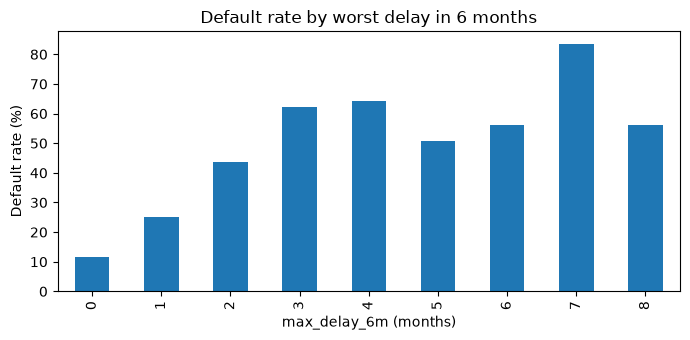

In [10]:
for col, bins in [("max_delay_6m", None), ("utilisation_1", 4)]:
    if bins is None:
        grp = features.groupby(col)["default_payment_next_month"]
    else:
        grp = features.groupby(pd.qcut(features[col], bins, duplicates="drop"),
                               observed=True)["default_payment_next_month"]
    t = grp.agg(n="size", default_rate="mean").reset_index()
    t["default_rate_pct"] = (t["default_rate"] * 100).round(1)
    print(f"--- {col} ---")
    print(t.to_string(index=False))
    print()

ax = features.groupby("max_delay_6m")["default_payment_next_month"].mean().mul(100).plot(
    kind="bar", figsize=(7, 3.5), legend=False)
ax.set_title("Default rate by worst delay in 6 months")
ax.set_xlabel("max_delay_6m (months)")
ax.set_ylabel("Default rate (%)")
plt.tight_layout()
plt.show()

## 下一步

1. 將上面觀察到的 3–5 個主要發現寫入 `reports/findings.md` 初稿（每個發現指向具體圖表或數字）。
2. 去 `02_baseline_logistic.ipynb`：用同一份 `credit_features.csv`，分層 80／20 切分，做 logistic regression baseline。